# Etapa 4: Modelado Teórico de Atenuación y Catálogo de Ganancias (Wang)

Este notebook implementa el **Paso 4**: el cálculo analítico de las curvas de atenuación anelástica y la generación del catálogo teórico de compensación de amplitudes estabilizadas de Wang.

### Formulación Física y Matemática
El decaimiento teórico de la amplitud con la distancia y el tiempo está regido por:

$$\beta(X, Q) = \exp\left( -\frac{\pi X}{Q} \right) = \exp\left( -\frac{\omega t}{2Q} \right)$$

donde $X = f \cdot t$ es la variable adimensional del producto tiempo por frecuencia.

Para compensar la amplitud sin amplificar de forma descontrolada el ruido en altas frecuencias, se define el parámetro de regularización de Wang con límite de ganancia $G_{\lim} = 20\text{ dB}$:

$$\sigma = \exp\left( -(0.23 \cdot G_{\lim} + 1.63) \right)$$

$$\text{Ganancia}(X, Q) = \frac{\beta(X, Q) + \sigma}{\beta^2(X, Q) + \sigma}$$

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

MODULE_DIR = os.path.abspath('../3_Python_Code')
if MODULE_DIR not in sys.path:
    sys.path.insert(0, MODULE_DIR)

from config import QInversionConfig
from q_theoretical import compute_theoretical_attenuation

print('Módulo teórico cargado.')

Módulo teórico cargado.


## 1. Generación de la Base Teórica en función de Q

Exploramos el catálogo continuo para factores de calidad desde $Q = 10$ hasta $Q = 140$ y valores del producto tiempo-frecuencia $X$ de $1$ a $250$.

In [2]:
q_cfg = QInversionConfig(
    q_min=10.0,
    q_max=140.0,
    dq=0.5,
    x_min=1.0,
    x_max=220.0,
    dx=1.0,
    gain_limit_db=20.0
)

beta, gan_teorica, x_vec, q_vec = compute_theoretical_attenuation(q_cfg)
print(f'Matriz Beta(X, Q): {beta.shape}')
print(f'Matriz de Ganancia Teórica: {gan_teorica.shape}')
print(f'Factor de estabilización desvi (Glim=20 dB): {q_cfg.desvi:.6f}')

Matriz Beta(X, Q): (220, 261)
Matriz de Ganancia Teórica: (220, 261)
Factor de estabilización desvi (Glim=20 dB): 0.001969


## 2. Inspección del Catálogo Teórico

Comparamos cómo varía la atenuación espectral $\beta(X, Q)$ y la ganancia estabilizada resultante para medios de alta disipación ($Q=15$) frente a medios poco atenuantes ($Q=100$).

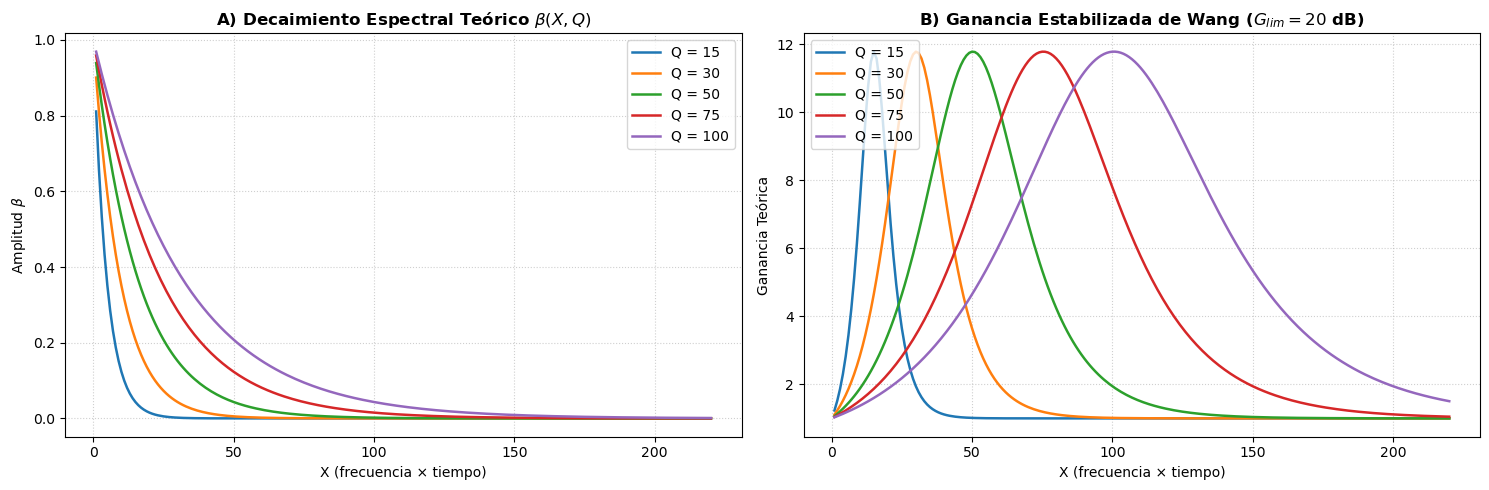

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

q_targets = [15, 30, 50, 75, 100]
for q_t in q_targets:
    idx_q = int(np.argmin(np.abs(q_vec - q_t)))
    axes[0].plot(x_vec, beta[:, idx_q], label=f'Q = {q_vec[idx_q]:.0f}', linewidth=1.8)
axes[0].set_title('A) Decaimiento Espectral Teórico $\\beta(X, Q)$', fontweight='bold')
axes[0].set_xlabel('X (frecuencia × tiempo)')
axes[0].set_ylabel('Amplitud $\\beta$')
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.6)

for q_t in q_targets:
    idx_q = int(np.argmin(np.abs(q_vec - q_t)))
    axes[1].plot(x_vec, gan_teorica[:, idx_q], label=f'Q = {q_vec[idx_q]:.0f}', linewidth=1.8)
axes[1].set_title('B) Ganancia Estabilizada de Wang ($G_{lim}=20$ dB)', fontweight='bold')
axes[1].set_xlabel('X (frecuencia × tiempo)')
axes[1].set_ylabel('Ganancia Teórica')
axes[1].legend(loc='upper left')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()